loading CLF and TEST sets ...
CLF=100000  TEST=100000

[1-2] boxcar baselines
  boxcar, full window (LDA)          F=0.9578  (F0=0.9752, F1=0.9404)
  tuned window on CLF: bins [50, 530)  (CLF fidelity 0.9603)
  boxcar, tuned [50,530) (LDA)       F=0.9605  (F0=0.9770, F1=0.9440)

[3-4] dual-filter features
  lin4 @ T=500 (ridge)               F=0.9610  (F0=0.9767, F1=0.9454)
  full quad @ T=500 (ridge)          F=0.9614  (F0=0.9759, F1=0.9470)

[5] small NN on the 4 filter features
  NN (16,8) on 4 filter features     F=0.9607  (F0=0.9733, F1=0.9480)  [8 epochs, 200 mults]

[6] NN on the raw trace (this is the slow one)
  NN (128,32) on raw trace T=500     F=0.9592  (F0=0.9741, F1=0.9444)  [8 epochs, 132128 mults]

====================== SUMMARY (full test set) ======================
method                                     F    vs tuned boxcar (pts)  front-end MACs  classifier mults
boxcar, full window (LDA)             0.9578      -0.27 +/- 0.03               0                 2
box

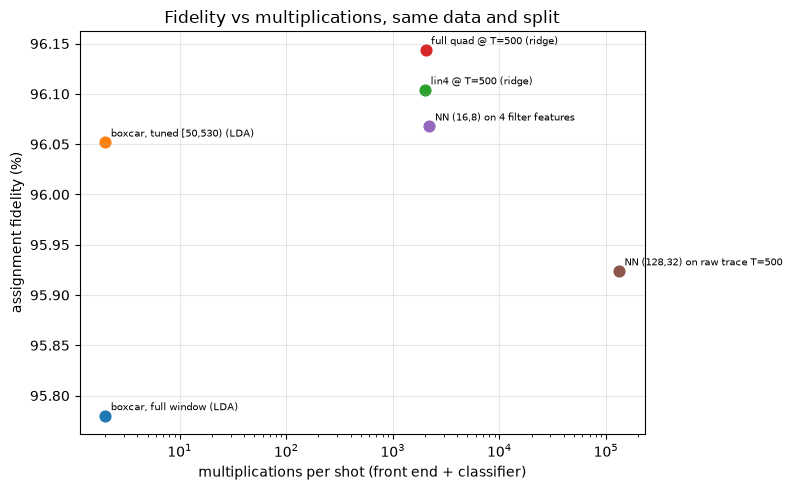

In [1]:
"""
Step 6: fair baselines on the QICK single-qubit data.

Methods, all trained on the same CLF set and scored on the same full TEST set:
  1. boxcar, full window           (plain average of the whole trace, Fisher LDA on [sum I, sum Q])
  2. boxcar, TUNED window [a, b)   (window start/end searched on CLF; the fair simple baseline)
  3. lin4        @ T=500           (your dual-filter features, ridge)
  4. full quad   @ T=500           (adds the 10 pairwise products)
  5. NN on the 4 filter features   (does a nonlinear net on the SAME features beat quadratic terms?)
  6. NN on raw trace (T=500)       (rough nonlinear ceiling, Lienhard-style FNN, no filters)

Also prints multiplication counts and saves a fidelity-vs-multiplications plot.
Needs step2_filters.npz and scikit-learn (pip install scikit-learn).
"""
import os
import numpy as np
import matplotlib.pyplot as plt

try:
    from sklearn.neural_network import MLPClassifier
except ImportError:
    raise SystemExit("Please run:  pip install scikit-learn")

# ------------------------------------------------------------------ config
DATA_DIR = r"D:\MSU\Qubit_readout_FPGA\python"
FILTER_FILE = "step2_filters.npz"
ALPHA_KEY = "0.05"
T_FEAT = 500                 # accumulation length for the filter features and the raw-trace NN
N_SAMPLES = 770
CH = 20_000
RIDGE_LAMBDA = 1e-3
SEED = 0


def p(name):
    return os.path.join(DATA_DIR, name)


# ------------------------------------------------------------------ load
if not os.path.exists(FILTER_FILE):
    raise FileNotFoundError(f"{FILTER_FILE} not found. Run step1_2_filters_baselines.py to the end first.")
z = np.load(FILTER_FILE)
clf_idx = z["clf_idx"]
W = [z[f"{k}_a{ALPHA_KEY}"] for k in ("Wmf_I", "Wmf_Q", "Wrmf_I", "Wrmf_Q")]

Xtr = np.load(p("0528_X_train_0_770.npy"), mmap_mode="r")
Xte_m = np.load(p("0528_X_test_0_770.npy"), mmap_mode="r")
ytr = np.load(p("0528_y_train_0_770.npy")).astype(int)
yte = np.load(p("0528_y_test_0_770.npy")).astype(int)


def load_rows(X, idx):
    out = np.empty((len(idx), X.shape[1]), np.float32)
    for i in range(0, len(idx), CH):
        out[i:i + CH] = X[idx[i:i + CH]]
    return out


print("loading CLF and TEST sets ...")
Xclf, yclf = load_rows(Xtr, clf_idx), ytr[clf_idx]
Xte = load_rows(Xte_m, np.arange(len(yte)))
print(f"CLF={len(yclf)}  TEST={len(yte)}")


# ------------------------------------------------------------------ helpers
def best_threshold(s, y):
    order = np.argsort(s)
    ss, ys = s[order], y[order]
    n0 = (ys == 0).sum()
    c1 = np.r_[0, np.cumsum(ys == 1)]
    c0 = np.r_[0, np.cumsum(ys == 0)]
    k = int(np.argmin(c1 + (n0 - c0)))
    if k == 0:
        return ss[0] - 1.0
    if k == len(ss):
        return ss[-1]
    return 0.5 * (ss[k - 1] + ss[k])


def fid(pred, y):
    f0, f1 = np.mean(~pred[y == 0]), np.mean(pred[y == 1])
    return f0, f1, 0.5 * (f0 + f1)


def lda_fit(F, y):
    m0, m1 = F[y == 0].mean(0), F[y == 1].mean(0)
    Sw = 0.5 * (np.cov(F[y == 0].T) + np.cov(F[y == 1].T))
    return np.linalg.solve(Sw, m1 - m0)


def ridge_fit(F, y, lam=RIDGE_LAMBDA):
    mu, sd = F.mean(0), F.std(0) + 1e-12
    Z = np.c_[np.ones(len(F)), (F - mu) / sd]
    w = np.linalg.solve(Z.T @ Z + lam * np.eye(Z.shape[1]), Z.T @ (2.0 * y - 1.0))
    return mu, sd, w


def ridge_score(F, m):
    mu, sd, w = m
    return np.c_[np.ones(len(F)), (F - mu) / sd] @ w


results = []


def record(name, s_clf, s_te, front, clf, note=""):
    thr = best_threshold(s_clf, yclf)
    pred = s_te > thr
    f0, f1, F = fid(pred, yte)
    results.append(dict(name=name, F=F, f0=f0, f1=f1, front=front, clf=clf,
                        correct=(pred == (yte == 1)), note=note))
    print(f"  {name:<34s} F={F:.4f}  (F0={f0:.4f}, F1={f1:.4f})")


# ------------------------------------------------------------------ 1+2. boxcar, full and tuned window
print("\n[1-2] boxcar baselines")


def cumsums(X):
    N = len(X)
    cI = np.zeros((N, N_SAMPLES + 1))
    cQ = np.zeros((N, N_SAMPLES + 1))
    for i in range(0, N, CH):
        x = X[i:i + CH]
        cI[i:i + CH, 1:] = np.cumsum(x[:, 0::2], axis=1, dtype=np.float64)
        cQ[i:i + CH, 1:] = np.cumsum(x[:, 1::2], axis=1, dtype=np.float64)
    return cI, cQ


cIc, cQc = cumsums(Xclf)


def box_feats(cI, cQ, a, b):
    return np.c_[cI[:, b] - cI[:, a], cQ[:, b] - cQ[:, a]]


Fc = box_feats(cIc, cQc, 0, N_SAMPLES)
w = lda_fit(Fc, yclf)
cIt, cQt = cumsums(Xte)
Ft = box_feats(cIt, cQt, 0, N_SAMPLES)
record("boxcar, full window (LDA)", Fc @ w, Ft @ w, front=0, clf=2)

best = None
for a in range(0, 301, 25):
    for b in range(a + 50, N_SAMPLES + 1, 10):
        Fc = box_feats(cIc, cQc, a, b)
        w = lda_fit(Fc, yclf)
        s = Fc @ w
        F = fid(s > best_threshold(s, yclf), yclf)[2]
        if best is None or F > best[0]:
            best = (F, a, b)
_, a_best, b_best = best
print(f"  tuned window on CLF: bins [{a_best}, {b_best})  (CLF fidelity {best[0]:.4f})")
Fc, Ft = box_feats(cIc, cQc, a_best, b_best), box_feats(cIt, cQt, a_best, b_best)
w = lda_fit(Fc, yclf)
record(f"boxcar, tuned [{a_best},{b_best}) (LDA)", Fc @ w, Ft @ w, front=0, clf=2)
del cIc, cQc, cIt, cQt


# ------------------------------------------------------------------ 3+4. dual-filter features, lin4 and full quad
def filt4(X, T=T_FEAT):
    out = np.empty((len(X), 4))
    for i in range(0, len(X), CH):
        x = X[i:i + CH]
        I, Q = x[:, 0:2 * T:2].astype(np.float64), x[:, 1:2 * T:2].astype(np.float64)
        out[i:i + CH] = np.c_[I @ W[0][:T], Q @ W[1][:T], I @ W[2][:T], Q @ W[3][:T]]
    return out


print("\n[3-4] dual-filter features")
Fc4, Ft4 = filt4(Xclf), filt4(Xte)
mu_b, sd_b = Fc4.mean(0), Fc4.std(0) + 1e-12
Zc, Zt = (Fc4 - mu_b) / sd_b, (Ft4 - mu_b) / sd_b


def full_quad(Z):
    return np.c_[Z, np.stack([Z[:, i] * Z[:, j] for i in range(4) for j in range(i, 4)], 1)]


m = ridge_fit(Zc, yclf)
record(f"lin4 @ T={T_FEAT} (ridge)", ridge_score(Zc, m), ridge_score(Zt, m), front=4 * T_FEAT, clf=5)
m = ridge_fit(full_quad(Zc), yclf)
record(f"full quad @ T={T_FEAT} (ridge)", ridge_score(full_quad(Zc), m), ridge_score(full_quad(Zt), m),
       front=4 * T_FEAT, clf=10 + 15)


# ------------------------------------------------------------------ 5+6. small neural networks
def train_mlp(Ftrain, Fte_, hidden, max_iter, name, front):
    n_hold = len(Ftrain) // 10
    Xa, ya = Ftrain[:-n_hold], yclf[:-n_hold]
    Xh, yh = Ftrain[-n_hold:], yclf[-n_hold:]
    net = MLPClassifier(hidden_layer_sizes=hidden, activation="relu", solver="adam", batch_size=512,
                        learning_rate_init=1e-3, max_iter=max_iter, early_stopping=True,
                        validation_fraction=0.1, n_iter_no_change=5, random_state=SEED)
    net.fit(Xa, ya)
    thr = best_threshold(net.predict_proba(Xh)[:, 1], yh)      # threshold on held-out shots
    s_te = net.predict_proba(Fte_)[:, 1]
    sizes = [Ftrain.shape[1], *hidden, 1]
    n_mult = sum(sizes[i] * sizes[i + 1] for i in range(len(sizes) - 1))
    pred = s_te > thr
    f0, f1, F = fid(pred, yte)
    results.append(dict(name=name, F=F, f0=f0, f1=f1, front=front, clf=n_mult,
                        correct=(pred == (yte == 1)), note=f"{net.n_iter_} epochs"))
    print(f"  {name:<34s} F={F:.4f}  (F0={f0:.4f}, F1={f1:.4f})  [{net.n_iter_} epochs, {n_mult} mults]")


print("\n[5] small NN on the 4 filter features")
train_mlp(Zc, Zt, (16, 8), 80, "NN (16,8) on 4 filter features", front=4 * T_FEAT)

print("\n[6] NN on the raw trace (this is the slow one)")
cols = slice(0, 2 * T_FEAT)
mu_r = Xclf[:, cols].mean(0, dtype=np.float64)
sd_r = Xclf[:, cols].std(0, dtype=np.float64) + 1e-6
Rc = ((Xclf[:, cols] - mu_r) / sd_r).astype(np.float32)
Rt = ((Xte[:, cols] - mu_r) / sd_r).astype(np.float32)
train_mlp(Rc, Rt, (128, 32), 40, f"NN (128,32) on raw trace T={T_FEAT}", front=0)

# ------------------------------------------------------------------ summary
ref = next(r for r in results if r["name"].startswith("boxcar, tuned"))
print("\n====================== SUMMARY (full test set) ======================")
print(f"{'method':<36s} {'F':>7s} {'vs tuned boxcar (pts)':>24s} {'front-end MACs':>15s} {'classifier mults':>17s}")
for r in results:
    d = r["correct"].astype(float) - ref["correct"].astype(float)
    print(f"{r['name']:<36s} {r['F']:7.4f} {100 * d.mean():+10.2f} +/- {100 * d.std() / np.sqrt(len(d)):.2f}"
          f" {r['front']:15d} {r['clf']:17d}")
print("\nHow to read: a method is only 'better' than tuned boxcar if its gain is clearly larger than its +/- value.")
print("Front-end MACs run at ADC rate for every shot; the NN-on-raw-trace row has them folded into its first layer.")

plt.figure(figsize=(8, 5))
for r in results:
    x = max(r["front"] + r["clf"], 1)
    plt.scatter(x, 100 * r["F"], s=60)
    plt.annotate(r["name"], (x, 100 * r["F"]), fontsize=7, xytext=(4, 4), textcoords="offset points")
plt.xscale("log")
plt.xlabel("multiplications per shot (front end + classifier)")
plt.ylabel("assignment fidelity (%)")
plt.title("Fidelity vs multiplications, same data and split")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("step6_baselines.png", dpi=130)
print("saved step6_baselines.png")